In [71]:
import torch
import pandas as pd
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from torch.utils.data import DataLoader, Dataset
from tqdm.auto import tqdm

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np

DATA_FOLDER = '../data/'

In [3]:
# 1. Configuración de Hardware
device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
model_name = "ProsusAI/finbert"

tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSequenceClassification.from_pretrained(model_name).to(device)
model.eval()

# Mapeo de índices de FinBERT: 0 -> positive, 1 -> negative, 2 -> neutral
labels_map = model.config.id2label

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 16842.58it/s]


In [4]:
# 2. Dataset eficiente para PyTorch
class HeadlineDataset(Dataset):
    def __init__(self, texts, tokenizer, max_len=64):
        self.texts = texts
        self.tokenizer = tokenizer
        self.max_len = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        text = str(self.texts[idx])
        encoding = self.tokenizer(
            text,
            truncation=True,
            padding="max_length",
            max_length=self.max_len,
            return_tensors="pt"
        )
        return {
            "input_ids": encoding["input_ids"].squeeze(0),
            "attention_mask": encoding["attention_mask"].squeeze(0)
        }

In [13]:
df = pd.read_csv(DATA_FOLDER + 'bezinga_articles_2009-2020/raw_partner_headlines.csv')
df

,Unnamed: 0,headline,url,publisher,date,stock
0,2,Agilent Technologies Announces Pricing of $5……...,http://www.gurufocus.com/news/1153187/agilent-...,GuruFocus,2020-06-01 00:00:00,A
1,3,Agilent (A) Gears Up for Q2 Earnings: What's i...,http://www.zacks.com/stock/news/931205/agilent...,Zacks,2020-05-18 00:00:00,A
2,4,J.P. Morgan Asset Management Announces Liquida...,http://www.gurufocus.com/news/1138923/jp-morga...,GuruFocus,2020-05-15 00:00:00,A
3,5,"Pershing Square Capital Management, L.P. Buys ...",http://www.gurufocus.com/news/1138704/pershing...,GuruFocus,2020-05-15 00:00:00,A
4,6,Agilent Awards Trilogy Sciences with a Golden ...,http://www.gurufocus.com/news/1134012/agilent-...,GuruFocus,2020-05-12 00:00:00,A
...,...,...,...,...,...,...
1845554,1849874,Consumer Cyclical Sector Wrap,https://www.benzinga.com/content/12/08/2846030...,webmaster,2012-08-20 00:00:00,ZX
1845555,1849875,Consumer Cyclical Sector Wrap,https://www.benzinga.com/content/12/07/2767124...,webmaster,2012-07-23 00:00:00,ZX
1845556,1849876,Zacks #5 Rank Additions for Monday - Tale of t...,http://www.zacks.com/stock/news/73497/here-are...,Zacks,2012-04-23 00:00:00,ZX
1845557,1849877,4 Stock Strategies From Wall Street: Feb. 9 (U...,http://www.thestreet.com/story/11409053/1/4-st...,TheStreet.Com,2012-02-09 00:00:00,ZX


In [18]:
df = pd.read_csv(DATA_FOLDER + 'bezinga_articles_2009-2020/raw_analyst_ratings.csv')
df

,Unnamed: 0,headline,url,publisher,date,stock
0,0,Stocks That Hit 52-Week Highs On Friday,https://www.benzinga.com/news/20/06/16190091/s...,Benzinga Insights,2020-06-05 10:30:54-04:00,A
1,1,Stocks That Hit 52-Week Highs On Wednesday,https://www.benzinga.com/news/20/06/16170189/s...,Benzinga Insights,2020-06-03 10:45:20-04:00,A
2,2,71 Biggest Movers From Friday,https://www.benzinga.com/news/20/05/16103463/7...,Lisa Levin,2020-05-26 04:30:07-04:00,A
3,3,46 Stocks Moving In Friday's Mid-Day Session,https://www.benzinga.com/news/20/05/16095921/4...,Lisa Levin,2020-05-22 12:45:06-04:00,A
4,4,B of A Securities Maintains Neutral on Agilent...,https://www.benzinga.com/news/20/05/16095304/b...,Vick Meyer,2020-05-22 11:38:59-04:00,A
...,...,...,...,...,...,...
1407323,1413844,Top Narrow Based Indexes For August 29,https://www.benzinga.com/news/11/08/1888782/to...,Monica Gerson,2011-08-29 00:00:00,ZX
1407324,1413845,Recap: Wednesday's Top Percentage Gainers and ...,https://www.benzinga.com/news/earnings/11/06/1...,Benjamin Lee,2011-06-22 00:00:00,ZX
1407325,1413846,UPDATE: Oppenheimer Color on China Zenix Auto ...,https://www.benzinga.com/analyst-ratings/analy...,BenzingaStaffL,2011-06-21 00:00:00,ZX
1407326,1413847,Oppenheimer Initiates China Zenix At Outperfor...,https://www.benzinga.com/analyst-ratings/price...,Joe Young,2011-06-21 00:00:00,ZX


In [ ]:
df_news = pd.read_csv(DATA_FOLDER + 'bezinga_articles_2009-2020/analyst_ratings_processed.csv')
df_news

,Unnamed: 0,title,date,stock
0,0.0,Stocks That Hit 52-Week Highs On Friday,2020-06-05 10:30:00-04:00,A
1,1.0,Stocks That Hit 52-Week Highs On Wednesday,2020-06-03 10:45:00-04:00,A
2,2.0,71 Biggest Movers From Friday,2020-05-26 04:30:00-04:00,A
3,3.0,46 Stocks Moving In Friday's Mid-Day Session,2020-05-22 12:45:00-04:00,A
4,4.0,B of A Securities Maintains Neutral on Agilent...,2020-05-22 11:38:00-04:00,A
...,...,...,...,...
1400464,1413844.0,Top Narrow Based Indexes For August 29,2011-08-29 10:41:00-04:00,ZX
1400465,1413845.0,Recap: Wednesday's Top Percentage Gainers and ...,2011-06-22 16:44:00-04:00,ZX
1400466,1413846.0,UPDATE: Oppenheimer Color on China Zenix Auto ...,2011-06-21 08:26:00-04:00,ZX
1400467,1413847.0,Oppenheimer Initiates China Zenix At Outperfor...,2011-06-21 05:59:00-04:00,ZX


In [ ]:
dataset = HeadlineDataset(df_news["title"].tolist(), tokenizer)
loader = DataLoader(dataset, batch_size=32, shuffle=False)

# 4. Inferencia por batches
all_probs = []

with torch.no_grad():
    for batch in tqdm(loader, desc="Clasificando titulares"):
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)

        outputs = model(input_ids=input_ids, attention_mask=attention_mask)
        probs = torch.softmax(outputs.logits, dim=-1).cpu().numpy()
        all_probs.extend(probs)

# 5. Estructurar resultados
probs_df = pd.DataFrame(all_probs, columns=[labels_map[i] for i in range(3)])

# Métricas derivadas
df_news["pred_label"] = probs_df.idxmax(axis=1)
df_news["prob_positive"] = probs_df["positive"]
df_news["prob_negative"] = probs_df["negative"]
df_news["prob_neutral"] = probs_df["neutral"]

# Score neto continuo: [-1, +1]
df_news["net_sentiment"] = df_news["prob_positive"] - df_news["prob_negative"]

df_news.to_csv('BERT_bezinga.csv')

Clasificando titulares: 100%|██████████| 43765/43765 [49:16<00:00, 14.80it/s]


In [ ]:
df_news

,Unnamed: 0,title,date,stock,pred_label,prob_positive,prob_negative,prob_neutral,net_sentiment
0,0.0,Stocks That Hit 52-Week Highs On Friday,2020-06-05 10:30:00-04:00,A,neutral,0.211447,0.082010,0.706542,0.129437
1,1.0,Stocks That Hit 52-Week Highs On Wednesday,2020-06-03 10:45:00-04:00,A,neutral,0.261656,0.069670,0.668674,0.191986
2,2.0,71 Biggest Movers From Friday,2020-05-26 04:30:00-04:00,A,neutral,0.094137,0.109070,0.796793,-0.014934
3,3.0,46 Stocks Moving In Friday's Mid-Day Session,2020-05-22 12:45:00-04:00,A,neutral,0.067890,0.289631,0.642479,-0.221740
4,4.0,B of A Securities Maintains Neutral on Agilent...,2020-05-22 11:38:00-04:00,A,positive,0.662542,0.016243,0.321216,0.646299
...,...,...,...,...,...,...,...,...,...
1400464,1413844.0,Top Narrow Based Indexes For August 29,2011-08-29 10:41:00-04:00,ZX,neutral,0.028538,0.059121,0.912341,-0.030583
1400465,1413845.0,Recap: Wednesday's Top Percentage Gainers and ...,2011-06-22 16:44:00-04:00,ZX,neutral,0.070986,0.280330,0.648684,-0.209344
1400466,1413846.0,UPDATE: Oppenheimer Color on China Zenix Auto ...,2011-06-21 08:26:00-04:00,ZX,neutral,0.046789,0.020095,0.933115,0.026694
1400467,1413847.0,Oppenheimer Initiates China Zenix At Outperfor...,2011-06-21 05:59:00-04:00,ZX,neutral,0.250902,0.030708,0.718391,0.220194


In [ ]:
# 1. Convierte a datetime; lo que sea texto o basura ('AAN', etc.) se transforma en NaT
df_news['date'] = pd.to_datetime(df_news['date'], errors='coerce', utc=True).dt.tz_localize(None).dt.normalize()

# 2. (Recomendado) Inspecciona qué filas tenían texto inválido antes de descartarlas
basura = df_news[df_news['date'].isna()]
if not basura.empty:
    print(f"Se encontraron {len(basura)} filas con datos no válidos:")
    print(basura.head())

# 3. Elimina las filas donde la fecha era inválida
df_news = df_news.dropna(subset=['date'])

Se encontraron 2578 filas con datos no válidos:
       Unnamed: 0                                  title date stock  \
2298       5714.0  Sterne Agee Provides Color on Aaron's  NaT   NaN   
2299          NaN              2011-07-20 06:43:00-04:00  NaT   NaN   
3568       7021.0     Goldman Sachs Updates on Car Parts  NaT   NaN   
3569          NaN              2011-07-22 07:38:00-04:00  NaT   NaN   
10257     13735.0    American Campus to Offer 15M Shares  NaT   NaN   

      pred_label  prob_positive  prob_negative  prob_neutral  net_sentiment  
2298     neutral       0.036994       0.027645      0.935361       0.009348  
2299     neutral       0.024031       0.058688      0.917281      -0.034657  
3568     neutral       0.027207       0.060976      0.911817      -0.033770  
3569     neutral       0.022619       0.060764      0.916618      -0.038145  
10257    neutral       0.085753       0.010296      0.903951       0.075457  


In [52]:
df_news

,Unnamed: 0,title,date,stock,pred_label,prob_positive,prob_negative,prob_neutral,net_sentiment
0,0.0,Stocks That Hit 52-Week Highs On Friday,2020-06-05,A,neutral,0.211447,0.082010,0.706542,0.129437
1,1.0,Stocks That Hit 52-Week Highs On Wednesday,2020-06-03,A,neutral,0.261656,0.069670,0.668674,0.191986
2,2.0,71 Biggest Movers From Friday,2020-05-26,A,neutral,0.094137,0.109070,0.796793,-0.014934
3,3.0,46 Stocks Moving In Friday's Mid-Day Session,2020-05-22,A,neutral,0.067890,0.289631,0.642479,-0.221740
4,4.0,B of A Securities Maintains Neutral on Agilent...,2020-05-22,A,positive,0.662542,0.016243,0.321216,0.646299
...,...,...,...,...,...,...,...,...,...
1400464,1413844.0,Top Narrow Based Indexes For August 29,2011-08-29,ZX,neutral,0.028538,0.059121,0.912341,-0.030583
1400465,1413845.0,Recap: Wednesday's Top Percentage Gainers and ...,2011-06-22,ZX,neutral,0.070986,0.280330,0.648684,-0.209344
1400466,1413846.0,UPDATE: Oppenheimer Color on China Zenix Auto ...,2011-06-21,ZX,neutral,0.046789,0.020095,0.933115,0.026694
1400467,1413847.0,Oppenheimer Initiates China Zenix At Outperfor...,2011-06-21,ZX,neutral,0.250902,0.030708,0.718391,0.220194


In [40]:
df_gold = pd.read_csv(DATA_FOLDER + 'panel_precios_niveles.csv')
df_gold.rename(columns = {'Unnamed: 0' : 'date'}, inplace = True)

In [63]:
# ------------------------------------------------------------------------------
# 1. Asegurar normalización de fechas en ambos DataFrames
# ------------------------------------------------------------------------------
df_news["date"] = pd.to_datetime(df_news["date"]).dt.tz_localize(None).dt.normalize()
df_gold["date"] = pd.to_datetime(df_gold["date"]).dt.tz_localize(None).dt.normalize()

# ------------------------------------------------------------------------------
# 2. Agregación Numérica Diaria (Sumatorias y Conteo)
# ------------------------------------------------------------------------------
# Columnas numéricas a sumar
cols_prob = ["prob_positive", "prob_negative", "prob_neutral", "net_sentiment"]

# Agregaciones vectorizadas rápidas
df_agg_metricas = (
    df_news.groupby("date")[cols_prob]
    .sum()
    .rename(
        columns={
            "prob_positive": "sum_prob_pos",
            "prob_negative": "sum_prob_neg",
            "prob_neutral": "sum_prob_neu",
            "net_sentiment": "sum_net_sentiment",
        }
    )
)

# Conteo de noticias por día (proxy de volumen de atención mediática)
df_agg_metricas["n_news"] = df_news.groupby("date")["title"].count()

# Sentimiento medio normalizado por volumen (evita sesgo en días con 50+ noticias)
df_agg_metricas["mean_net_sentiment"] = (
    df_agg_metricas["sum_net_sentiment"] / df_agg_metricas["n_news"]
)

# ------------------------------------------------------------------------------
# 3. Empaquetar la Estructura Anidada de Metadatos
# ------------------------------------------------------------------------------
# Seleccionamos las columnas que quieres conservar en el detalle
detalle_cols = [
    "stock",
    "title",
    "pred_label",
    "prob_positive",
    "prob_negative",
    "prob_neutral",
    "net_sentiment",
]

# Convertimos cada grupo diario en una lista de diccionarios
series_anidada = (
    df_news.groupby("date")
    .apply(
        lambda g: g[detalle_cols].to_dict(orient="records"),
        include_groups=False,  # Compatible con Pandas >= 2.2
    )
    .rename("news_items")
)

# Unir agregados numéricos y estructura anidada en un solo DataFrame diario
df_news_diario = df_agg_metricas.join(series_anidada)

# ------------------------------------------------------------------------------
# 4. Merge con el DataFrame de gold (df_gold)
# ------------------------------------------------------------------------------
# Left join: se conservan todos los días bursátiles del gold
df_panel_completo = df_news_diario.merge(df_gold, on="date", how="left")

# ------------------------------------------------------------------------------
# 5. Tratamiento de días sin noticias (Feriados / Días sin cobertura)
# ------------------------------------------------------------------------------
# Días sin noticias tendrán 0 en conteos y sumas de sentimiento
cols_a_cero = [
    "sum_prob_pos",
    "sum_prob_neg",
    "sum_prob_neu",
    "sum_net_sentiment",
    "mean_net_sentiment",
    "n_news",
]
df_panel_completo[cols_a_cero] = df_panel_completo[cols_a_cero].fillna(0)

# Días sin noticias tendrán lista vacía [] en lugar de NaN
df_panel_completo["news_items"] = df_panel_completo["news_items"].apply(
    lambda x: x if isinstance(x, list) else []
)

df_panel_completo = df_panel_completo.set_index('date')

In [73]:
variables = ['COMEX_Futuros_USD', 'LBMA_Proxy_Spot_USD', 'SGE_Au9999_RMB_g', 'SHFE_Futuros_RMB_g']

# 1. Calcular retornos porcentuales y prefijar nombres
df_pct = df_panel_completo[variables].pct_change().add_prefix('pct_diff_')

# 2. Calcular retornos logarítmicos y prefijar nombres
df_log = np.log(df_panel_completo[variables]).diff().add_prefix('log_diff_')

# 3. Concatenar todo al DataFrame original en una sola operación
df_panel_completo = pd.concat([df_panel_completo, df_pct, df_log], axis=1)

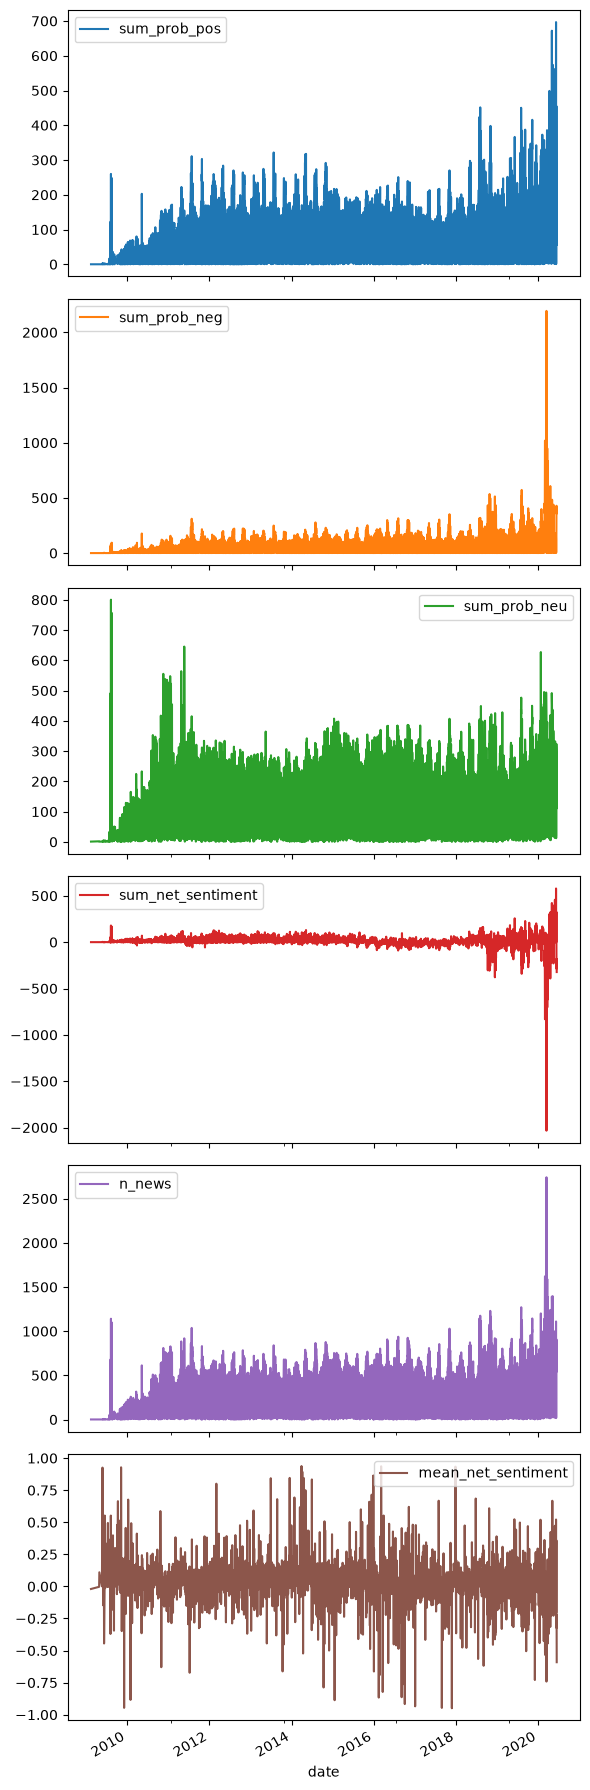

In [67]:
df_panel_completo.loc[:, 'sum_prob_pos':'mean_net_sentiment'].plot(
    subplots=True,
    sharex=  True,
    figsize=(6, 18)
)
plt.tight_layout()

<Axes: xlabel='sum_net_sentiment', ylabel='log_diff_COMEX_Futuros_USD'>

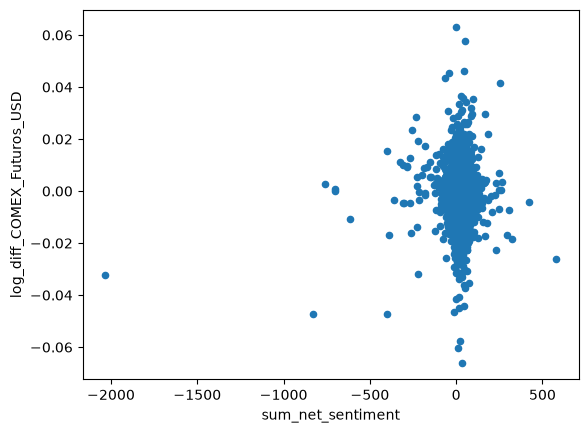

In [78]:
df_panel_completo.plot.scatter(
    x = 'sum_net_sentiment',
    y = 'log_diff_COMEX_Futuros_USD'
)

In [74]:
df_panel_completo

,sum_prob_pos,sum_prob_neg,sum_prob_neu,sum_net_sentiment,n_news,mean_net_sentiment,news_items,COMEX_Futuros_USD,LBMA_Proxy_Spot_USD,SGE_Au9999_RMB_g,...,SGE_Spot_USD_oz,SHFE_Futuros_USD_oz,pct_diff_COMEX_Futuros_USD,pct_diff_LBMA_Proxy_Spot_USD,pct_diff_SGE_Au9999_RMB_g,pct_diff_SHFE_Futuros_RMB_g,log_diff_COMEX_Futuros_USD,log_diff_LBMA_Proxy_Spot_USD,log_diff_SGE_Au9999_RMB_g,log_diff_SHFE_Futuros_RMB_g
date,,,,,,,,,,,,,,,,,,,,,
2009-02-14,0.027792,0.047699,0.924509,-0.019908,1,-0.019908,"[{'stock': 'NAV', 'title': 'How Treasuries and...",NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2009-04-27,0.070034,0.076137,1.853829,-0.006103,2,-0.003051,"[{'stock': 'FT', 'title': 'Update on the Luxur...",907.400024,928.628513,NaN,...,NaN,919.159287,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2009-04-29,0.156559,0.046411,0.797031,0.110148,1,0.110148,"[{'stock': 'A', 'title': 'Going Against the He...",899.799988,921.534168,NaN,...,NaN,900.015491,-0.008376,-0.007640,NaN,-0.021000,-0.008411,-0.007669,NaN,-0.021223
2009-05-22,0.034948,0.034177,0.930875,0.000772,1,0.000772,"[{'stock': 'AM', 'title': 'Charles Sizemore Ra...",958.500000,982.253385,NaN,...,NaN,951.124429,0.065237,0.065889,NaN,0.056694,0.063197,0.063809,NaN,0.055145
2009-05-27,2.834886,0.056358,0.108756,2.778528,3,0.926176,"[{'stock': 'EPS', 'title': 'JVA perks to 39% g...",953.200012,974.950338,NaN,...,NaN,948.588772,-0.005529,-0.007435,NaN,-0.001920,-0.005545,-0.007463,NaN,-0.001921
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2020-06-07,6.587012,2.834558,22.578430,3.752454,32,0.117264,"[{'stock': 'AAPL', 'title': 'Apple's Top Suppl...",NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-06-08,455.192200,129.013977,323.793854,326.178223,908,0.359227,"[{'stock': 'AAN', 'title': 'Shares of several ...",1705.099976,1666.335734,384.22,...,1687.696386,1696.744990,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-06-09,142.622330,428.686188,311.691498,-286.063873,883,-0.323968,"[{'stock': 'AAPL', 'title': 'Why Apple's Stock...",1721.900024,1682.402262,384.61,...,1691.966117,1699.400720,0.009853,0.009642,0.001015,0.000052,0.009805,0.009596,0.001015,0.000052


In [79]:
# Variable de precio base (ejemplo con COMEX)
col_precio = 'COMEX_Futuros_USD'

horizontes = {
    '1d': 1,
    '1w': 5,
    '1m': 21
}

for etiqueta, h in horizontes.items():
    # Retorno logarítmico acumulado hacia adelante: ln(P_{t+h}) - ln(P_t)
    df_panel_completo[f'fwd_log_ret_{etiqueta}'] = np.log(df_panel_completo[col_precio].shift(-h) / df_panel_completo[col_precio])
    
    # Alternativa en retorno porcentual: (P_{t+h} - P_t) / P_t
    df_panel_completo[f'fwd_pct_ret_{etiqueta}'] = (df_panel_completo[col_precio].shift(-h) - df_panel_completo[col_precio]) / df_panel_completo[col_precio]

<Axes: xlabel='mean_net_sentiment', ylabel='fwd_pct_ret_1d'>

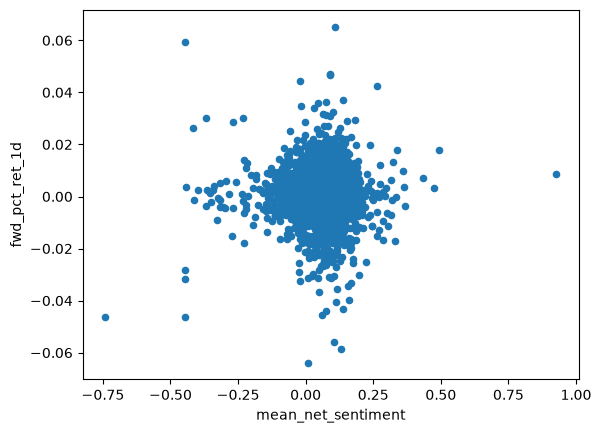

In [86]:
df_panel_completo.plot.scatter(
    x = 'mean_net_sentiment',
    y = 'fwd_pct_ret_1d'
)